# MNIST lab · Classifier guidance vs classifier-free guidance
**Seminar 8 · MIPT / YSDA · 12 November 2026**

Can a classifier steer a digit towards a requested label as reliably as the conditional denoiser? Compare both corrections to the **same** null-label prediction. Start with the saved grids and measurements below. To rerun, use a Colab GPU and run all cells in order.

The saved experiment uses the EMA denoiser and clean evaluator from [seminar 7](../seminar7/seminar7_ddpm_mnist.ipynb). To reproduce with those weights, place `mnist_cfg_checkpoint.pt` and `mnist_cfg_evaluator.pt` in the working directory. A fresh run without checkpoints trains both models locally. Results then depend on those new weights.

In [1]:
from pathlib import Path
import os, math, copy
import torch
from torch import nn
import torch.nn.functional as F
from torchvision.datasets import MNIST
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

torch.manual_seed(812)
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
weights = Path(os.environ.get('SEMINAR7_WEIGHTS', '.'))
data = Path(os.environ.get('MNIST_ROOT', './data'))
train = MNIST(data, train=True, download=True)
test = MNIST(data, train=False, download=True)
T, NULL = 200, 10
print(device, '·', len(train), 'training images')

mps · 60000 training images


In [2]:
def cosine_schedule(steps, offset=0.008):
    u = torch.linspace(0, steps, steps + 1, dtype=torch.float64)
    cumulative = torch.cos(((u / steps + offset) / (1 + offset)) * math.pi / 2).square()
    cumulative = cumulative / cumulative[0]
    betas = (1 - cumulative[1:] / cumulative[:-1]).clamp(1e-5, .999).float()
    alphas = 1 - betas
    abar = alphas.cumprod(0)
    previous = torch.cat([torch.ones(1), abar[:-1]])
    return {"beta": betas, "alpha": alphas, "abar": abar,
            "previous": previous,
            "posterior_var": betas * (1 - previous) / (1 - abar)}

schedule = {k: v.to(device) for k, v in cosine_schedule(T).items()}

def extract(values, t):
    return values[t].reshape(-1, 1, 1, 1)

def q_sample(x0, t, noise):
    a = extract(schedule["abar"], t)
    return a.sqrt() * x0 + (1-a).sqrt() * noise

### The shared denoiser
The eleventh embedding is the empty condition. Both samplers use exactly the same weights and the same null prediction. With seminar 7 weights, the denoiser has already seen both true and dropped labels.

In [3]:
class TimeEmbedding(nn.Module):
    def __init__(self, dim=128):
        super().__init__(); self.dim = dim
        self.mlp = nn.Sequential(nn.Linear(dim, dim), nn.SiLU(), nn.Linear(dim, dim))
    def forward(self, t):
        frequencies = torch.exp(-math.log(10000) * torch.arange(
            self.dim//2, device=t.device).float() / (self.dim//2-1))
        angles = t.float()[:, None] * frequencies[None]
        return self.mlp(torch.cat([angles.sin(), angles.cos()], dim=1))

class ResBlock(nn.Module):
    def __init__(self, cin, cout, time_dim=128):
        super().__init__()
        self.first = nn.Sequential(nn.GroupNorm(8, cin), nn.SiLU(), nn.Conv2d(cin, cout, 3, padding=1))
        self.time = nn.Linear(time_dim, cout)
        self.second = nn.Sequential(nn.GroupNorm(8, cout), nn.SiLU(), nn.Conv2d(cout, cout, 3, padding=1))
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
    def forward(self, x, emb):
        h = self.first(x) + self.time(F.silu(emb))[:, :, None, None]
        return self.skip(x) + self.second(h)

class TinyUNet(nn.Module):
    def __init__(self, base=32):
        super().__init__(); self.time = TimeEmbedding()
        self.input = nn.Conv2d(1, base, 3, padding=1)
        self.enc1 = ResBlock(base, base)
        self.down1 = nn.Conv2d(base, base*2, 4, stride=2, padding=1)
        self.enc2 = ResBlock(base*2, base*2)
        self.down2 = nn.Conv2d(base*2, base*4, 4, stride=2, padding=1)
        self.mid1 = ResBlock(base*4, base*4); self.mid2 = ResBlock(base*4, base*4)
        self.up2 = nn.Conv2d(base*4, base*2, 3, padding=1)
        self.dec2 = ResBlock(base*4, base*2)
        self.up1 = nn.Conv2d(base*2, base, 3, padding=1)
        self.dec1 = ResBlock(base*2, base)
        self.output = nn.Sequential(nn.GroupNorm(8, base), nn.SiLU(), nn.Conv2d(base, 1, 3, padding=1))
    def forward(self, x, t):
        return self.forward_with_embedding(x, self.time(t))

    def forward_with_embedding(self, x, e):
        h1 = self.enc1(self.input(x), e)
        h2 = self.enc2(self.down1(h1), e)
        h = self.mid2(self.mid1(self.down2(h2), e), e)
        h = self.up2(F.interpolate(h, size=h2.shape[-2:], mode="nearest"))
        h = self.dec2(torch.cat([h, h2], 1), e)
        h = self.up1(F.interpolate(h, size=h1.shape[-2:], mode="nearest"))
        return self.output(self.dec1(torch.cat([h, h1], 1), e))

class ConditionalUNet(TinyUNet):
    def __init__(self, base=32):
        super().__init__(base)
        self.class_embedding = nn.Embedding(10, 128)
        # Default unit-scale embeddings give distinct class signals from the start.

    def forward(self, x, t, y):
        e = self.time(t) + self.class_embedding(y)
        return self.forward_with_embedding(x, e)

class CFGUNet(ConditionalUNet):
    def __init__(self):
        super().__init__()
        self.class_embedding = nn.Embedding(11,128)

In [4]:
def batch(dataset, n):
    ix = torch.randint(len(dataset), (n,))
    return dataset.data[ix,None].to(device).float()/127.5-1, dataset.targets[ix].to(device)

net = CFGUNet().to(device)
cfg_file = weights / 'mnist_cfg_checkpoint.pt'
if cfg_file.exists():
    ckpt = torch.load(cfg_file, map_location='cpu', weights_only=True)
    assert ckpt['kind'] == 'classifier_free' and ckpt['T'] == T
    assert torch.allclose(ckpt['beta'].cpu(), schedule['beta'].cpu())
    net.load_state_dict(ckpt['ema'])
    print('Loaded seminar 7 EMA weights.')
else:
    ema = copy.deepcopy(net).requires_grad_(False)
    opt = torch.optim.Adam(net.parameters(), lr=0.001)
    for step in range(5000):
        x, y = batch(train, 64)
        t = torch.randint(T, (len(y),), device=device)
        eps = torch.randn_like(x)
        y = y.masked_fill(torch.rand(len(y), device=device) < 0.2, NULL)
        loss = F.mse_loss(net(q_sample(x,t,eps),t,y),eps)
        opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            for a,b in zip(ema.parameters(), net.parameters()):
                a.lerp_(b, 0.005)
    net = ema
    print('Trained a new denoiser with 20% label dropout.')
net.eval().requires_grad_(False);

Loaded seminar 7 EMA weights.


### Train the noisy classifier
Take a real labelled digit, sample a time $t$ and Gaussian noise, and construct $x_t$. Optimize $-\log p_\phi(y\mid x_t,t)$ for the original label. The extra input channel broadcasts the normalized time across the image. At the noisiest levels the image carries very little label information.

[Dhariwal & Nichol, Diffusion Models Beat GANs (2021)](https://arxiv.org/abs/2105.05233)

In [5]:
class NoisyClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(2,32,3,padding=1),nn.GroupNorm(4,32),nn.SiLU(),nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1),nn.GroupNorm(8,64),nn.SiLU(),nn.MaxPool2d(2),
            nn.Flatten(),nn.Linear(64*7*7,128),nn.SiLU(),nn.Linear(128,10))
    def forward(self,x,t):
        level = (t.float()/(T-1)).view(-1,1,1,1).expand_as(x)
        return self.layers(torch.cat([x,level],1))

torch.manual_seed(813)
guide = NoisyClassifier().to(device)
opt = torch.optim.AdamW(guide.parameters(), lr=0.0006)
for step in range(1600):
    x,y = batch(train,128)
    t = torch.randint(T,(len(y),),device=device)
    xt = q_sample(x,t,torch.randn_like(x))
    loss = F.cross_entropy(guide(xt,t),y)
    opt.zero_grad(); loss.backward(); opt.step()
guide.eval().requires_grad_(False)
with torch.no_grad():
    g = torch.Generator().manual_seed(814)
    idx = torch.randperm(len(test),generator=g)[:1000]
    x = test.data[idx,None].float()/127.5-1
    noise = torch.randn(x.shape,generator=g)
    for level in [0,50,100,150,199]:
        t = torch.full((len(x),),level,device=device,dtype=torch.long)
        noisy = q_sample(x.to(device),t,noise.to(device))
        pred = torch.cat([guide(a,b).argmax(1).cpu() for a,b in zip(noisy.split(128),t.split(128))])
        print(f't={level:3d}   held-out noisy-digit accuracy: {(pred==test.targets[idx]).float().mean():.1%}')

t=  0   held-out noisy-digit accuracy: 98.9%
t= 50   held-out noisy-digit accuracy: 98.4%
t=100   held-out noisy-digit accuracy: 96.2%
t=150   held-out noisy-digit accuracy: 75.1%
t=199   held-out noisy-digit accuracy: 9.2%


### Two guidance rules inside one DDIM loop
Write $\epsilon_u=\epsilon_\theta(x_t,t,\varnothing)$. For classifier guidance (CG), freeze the classifier and differentiate the requested class log probability **with respect to the noisy pixels**:
$$\widehat\epsilon_{\rm CG}=\epsilon_u-s\sqrt{1-\bar\alpha_t}\,\nabla_{x_t}\log p_\phi(y\mid x_t,t).$$
For CFG, evaluate the same denoiser with the requested label:
$$\widehat\epsilon_{\rm CFG}=\epsilon_u+s\bigl(\epsilon_\theta(x_t,t,y)-\epsilon_u\bigr).$$
Both formulas use the same score convention. Equal $s$ can produce corrections of different magnitudes with learned networks. Use deterministic DDIM ($\eta=0$), 50 reverse steps along the same time grid, and identical clipping of the clean-image estimate. CG adds a classifier forward and input-gradient pass. CFG adds one conditional denoiser pass.

In [6]:
@torch.no_grad()
def sample(start, labels, method, scale, states=None):
    x = start.to(device).clone()
    if states is not None:
        states.append(x.detach().cpu().clone())
    y = labels.to(device)
    empty = torch.full_like(y,NULL)
    times = np.rint(np.linspace(T-1,0,50)).astype(int).tolist()
    for now, nxt in zip(times, times[1:]+[-1]):
        t = torch.full_like(y,now)
        a = schedule['abar'][now]
        eps = net(x,t,empty)
        if scale and method == 'CG':
            with torch.enable_grad():
                xt = x.detach().requires_grad_(True)
                logp = guide(xt,t).log_softmax(1).gather(1,y[:,None])
                grad, = torch.autograd.grad(logp.sum(),xt)
            eps = eps - scale*(1-a).sqrt()*grad
        elif scale and method == 'CFG':
            eps = eps + scale*(net(x,t,y)-eps)
        clean = ((x-(1-a).sqrt()*eps)/a.sqrt()).clamp(-1,1)
        residual = (x-a.sqrt()*clean)/(1-a).sqrt()
        prev = schedule['abar'][nxt] if nxt>=0 else torch.ones_like(a)
        x = prev.sqrt()*clean + (1-prev).sqrt()*residual
        if states is not None:
            states.append(x.detach().cpu().clone())
    assert x.isfinite().all()
    return x.cpu()

per_class = 24
labels = torch.arange(10).repeat_interleave(per_class)
start = torch.randn((len(labels),1,28,28),generator=torch.Generator().manual_seed(815))
settings = [('CG',0), ('CG',1), ('CFG',1), ('CG',2), ('CFG',2), ('CG',4), ('CFG',4)]
samples = {}
for method,scale in settings:
    samples[method,scale] = torch.cat([sample(z,y,method,scale)
        for z,y in zip(start.split(48),labels.split(48))])
assert torch.allclose(samples['CG',0][:8], sample(start[:8],labels[:8],'CFG',0), atol=0.003, rtol=0.001)
print('Generated',len(labels),'paired samples per setting.')

Generated 240 paired samples per setting.


### Inspect the same seeds
Choose a digit. Each column starts from the same noise across all rows. Look for both the requested shape and changes in stroke width, loops and slant. The first row is the shared unconditional baseline.

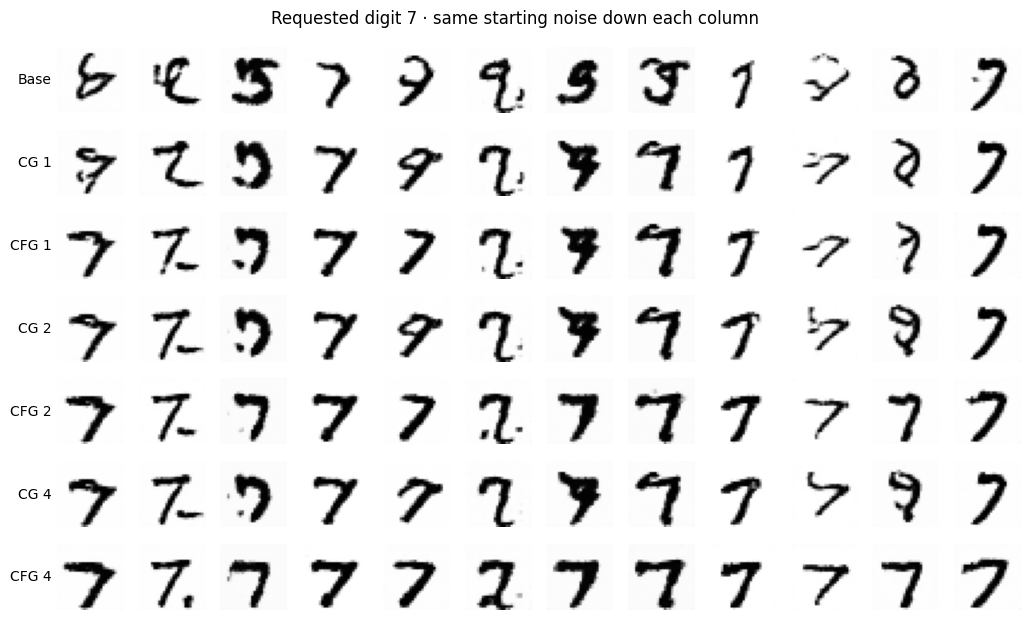

In [7]:
DIGIT = 7
cols = 12
fig, axes = plt.subplots(len(settings),cols,figsize=(10.4,6.3),facecolor='white')
for row,(method,scale) in enumerate(settings):
    for col,im in enumerate(samples[method,scale][labels==DIGIT][:cols]):
        ax = axes[row,col]
        ax.imshow(im[0],cmap='gray_r',vmin=-1,vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values(): spine.set_visible(False)
        if col==0: ax.set_ylabel(f'{method} {scale}' if scale else 'Base',rotation=0,ha='right',va='center')
fig.suptitle(f'Requested digit {DIGIT} · same starting noise down each column')
fig.tight_layout()
plt.show()

### Watch the reverse process · CG vs CFG
Each column follows one starting noise image. Both rows request a seven with guidance scale 2. Frame 0 shows the initial noise. Each following frame shows the actual image state after one deterministic DDIM step. The final frame pauses for three seconds. Change the digit or scale in the cell to replay the comparison.

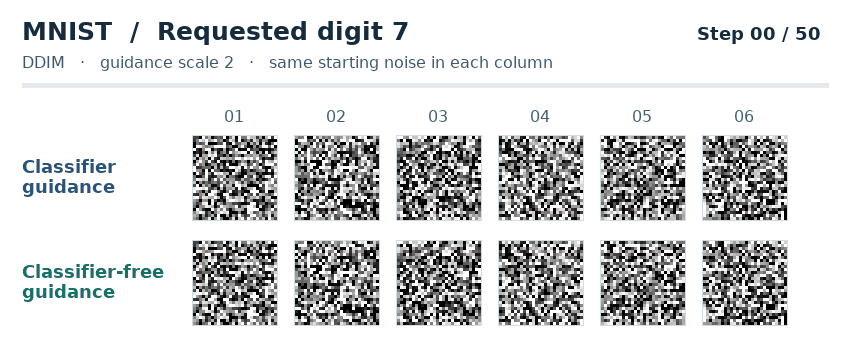

In [9]:
from io import BytesIO
from PIL import Image as PILImage, ImageDraw, ImageFont
from matplotlib import font_manager
from IPython.display import Image as DisplayImage

gif_digit, gif_scale = 7, 2
indices = torch.where(labels == gif_digit)[0][:6]
paths = {}
for method in ('CG', 'CFG'):
    states = []
    final = sample(start[indices], labels[indices], method, gif_scale, states=states)
    assert len(states) == 51 and torch.equal(final, states[-1])
    paths[method] = states
assert torch.equal(paths['CG'][0], paths['CFG'][0])

def gif_font(size, weight='normal'):
    path = font_manager.findfont(font_manager.FontProperties(family='DejaVu Sans', weight=weight))
    return ImageFont.truetype(path, size)

title_font, label_font, small_font = gif_font(25, 'bold'), gif_font(18, 'bold'), gif_font(16)
def draw_step(step):
    frame = PILImage.new('RGB', (850, 350), 'white')
    draw = ImageDraw.Draw(frame)
    draw.text((22, 16), f'MNIST  /  Requested digit {gif_digit}', font=title_font, fill='#162b3c')
    draw.text((22, 53), f'DDIM   ·   guidance scale {gif_scale}   ·   same starting noise in each column',
              font=small_font, fill='#41586b')
    draw.text((697, 23), f'Step {step:02d} / 50', font=label_font, fill='#162b3c')
    draw.rectangle((22, 83, 828, 87), fill='#e3e9ed')
    if step:
        draw.rectangle((22, 83, 22 + int(806*step/50), 87), fill='#197e72')
    for col in range(len(indices)):
        draw.text((224 + 102*col, 107), f'{col+1:02d}', font=small_font, fill='#486273')
    for row,(method, label) in enumerate([('CG', 'Classifier\nguidance'), ('CFG', 'Classifier-free\nguidance')]):
        y = 136 + row*105
        draw.multiline_text((22, y+20), label, font=label_font, fill='#26547c' if row == 0 else '#147367', spacing=3)
        for col, tensor in enumerate(paths[method][step]):
            # Fixed inverted grayscale, identical across images, methods and steps.
            pixels = ((1 - tensor[0].clamp(-1,1))*127.5).round().byte().numpy()
            tile = PILImage.fromarray(pixels).resize((84,84), PILImage.Resampling.NEAREST)
            x = 193 + col*102
            frame.paste(tile,(x,y))
            draw.rectangle((x-1,y-1,x+84,y+84),outline='#d2dbdf')
    return frame

frames = [draw_step(k) for k in range(51)]
buffer = BytesIO()
frames[0].save(buffer, format='GIF', save_all=True, append_images=frames[1:],
               duration=[1100] + [260]*49 + [3000], loop=0, optimize=True, disposal=1)
gif_bytes = buffer.getvalue()
display(DisplayImage(data=gif_bytes, format='gif'))


### Measure control and within-class diversity
A separate classifier trained on clean real MNIST evaluates final images. Agreement is the fraction assigned the requested digit. For diversity, keep only recognized matches, normalize their penultimate features, average pairwise Euclidean distances within each digit, then average equally over digits with at least two matches. Read the coverage alongside the distance. These features measure one aspect of variation.

In [8]:
class DigitEvaluator(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv=nn.Sequential(nn.Conv2d(1,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
                                nn.Conv2d(32,64,3,padding=1),nn.ReLU(),nn.MaxPool2d(2))
        self.features=nn.Sequential(nn.Flatten(),nn.Linear(64*7*7,128),nn.ReLU())
        self.head=nn.Linear(128,10)
    def forward(self,x,return_features=False):
        h=self.features(self.conv(x))
        return (self.head(h),h) if return_features else self.head(h)


judge = DigitEvaluator().to(device)
judge_file = weights / 'mnist_cfg_evaluator.pt'
if judge_file.exists():
    judge.load_state_dict(torch.load(judge_file,map_location='cpu',weights_only=True))
else:
    torch.manual_seed(816)
    opt = torch.optim.Adam(judge.parameters(),lr=0.001)
    for step in range(1600):
        x,y = batch(train,128)
        loss = F.cross_entropy(judge(x),y)
        opt.zero_grad(); loss.backward(); opt.step()
judge.eval().requires_grad_(False)

@torch.no_grad()
def assess(images):
    pairs = [judge(x.to(device),return_features=True) for x in images.split(128)]
    preds = torch.cat([a.argmax(1).cpu() for a,b in pairs])
    feats = F.normalize(torch.cat([b.cpu() for a,b in pairs]),dim=1)
    return preds,feats

pred,_ = assess(test.data[:,None].float()/127.5-1)
print(f'Independent evaluator on real MNIST test digits: {(pred==test.targets).float().mean():.2%}')
rows = []
for method,scale in settings:
    pred,feat = assess(samples[method,scale])
    ok = pred==labels
    distances = []
    for digit in range(10):
        subset = feat[ok & (labels==digit)]
        if len(subset)>=2: distances.append(torch.pdist(subset).mean().item())
    rows.append(dict(method=method if scale else 'Shared base',s=scale,
                     agreement=ok.float().mean().item(),matches=int(ok.sum()),
                     digits_scored=len(distances),diversity=np.mean(distances) if distances else np.nan))
results = pd.DataFrame(rows)
display(results.round(3))

Independent evaluator on real MNIST test digits: 98.60%


,method,s,agreement,matches,digits_scored,diversity
0,Shared base,0,0.125,30,9,0.620
1,CG,1,0.558,134,10,0.601
2,CFG,1,0.863,207,10,0.518
3,CG,2,0.729,175,10,0.572
4,CFG,2,0.992,238,10,0.399
5,CG,4,0.842,202,10,0.536
6,CFG,4,1.000,240,10,0.327


### Discuss the saved run

At $s=2$ the independent evaluator recognizes 72.9% of CG samples and 99.2% of CFG samples as the requested digit. Among recognized matches, the mean within-digit distances are 0.572 and 0.399, respectively. These estimates use 24 starts per digit and one training run.

Compare scales within each method. Which setting raises agreement most? Which still shows distinct handwriting? At a similar agreement, compare diversity and inspect the same columns in the grid. The numeric scale alone does not fix the size of the guidance update.